In [1]:
# ═══════════════════════════════════════════════════════════════════════
# VAR NOTEBOOK — Diversification Paradox
# ───────────────────────────────────────────────────────────────────────
# Reduced-form Vector Autoregression (VAR)
# 3 separate VARs — one per ETF flow fund (SPY, RSP, VOO)
# Each VAR is 5-variable: [dlog_vix, dy10, ASVI8, flow_x, mag7_ret]
# Cholesky ordering: macro first → narrative → flow → price outcome
# This ordering encodes the economic hypothesis: macro conditions are
# predetermined within the month, AI narrative attention responds to
# macro, ETF flows respond to attention, and prices are the final outcome
# ═══════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# Suppress KPSS interpolation warnings (cosmetic only — not an error)
warnings.filterwarnings("ignore")

from statsmodels.tsa.stattools import adfuller, kpss   # stationarity tests
from statsmodels.tsa.vector_ar.var_model import VAR     # VAR estimator

In [2]:
# ═══════════════════════════════════════════════════════════════════════
# DATA LOAD & MERGE
# ═══════════════════════════════════════════════════════════════════════

# Load each clean CSV — all produced in separate data preparation notebooks
spy  = pd.read_csv("spy_clean.csv",              parse_dates=["date"])  # SPY net flows (scaled by TNA)
voo  = pd.read_csv("voo_clean.csv",              parse_dates=["date"])  # VOO net flows
rsp  = pd.read_csv("rsp_clean.csv",              parse_dates=["date"])  # RSP net flows (equal-weight benchmark)
vix  = pd.read_csv("vix_clean.csv",              parse_dates=["date"])  # log-differenced VIX (macro risk proxy)
y10  = pd.read_csv("dgs10_clean.csv",            parse_dates=["date"])  # first-differenced 10Y Treasury yield
asvi8= pd.read_csv("AIStocks_ASVI8_Monthly.csv", parse_dates=["date"])  # ASVI8: abnormal AI search volume, 8-month median baseline
mag7 = pd.read_csv("mag7_clean.csv",             parse_dates=["date"])  # equal-weighted Mag7 log returns

# Sequential inner merge on date — keeps only months present in all series
# Inner join ensures no NaN rows from mismatched dates across sources
df = (spy
      .merge(rsp,   on="date", how="inner")
      .merge(voo,   on="date", how="inner")
      .merge(vix,   on="date", how="inner")
      .merge(y10,   on="date", how="inner")
      .merge(asvi8, on="date", how="inner")
      .merge(mag7,  on="date", how="inner")
)

# Sort chronologically and reset index to 0-based integer index
df = df.sort_values("date").reset_index(drop=True)

print(f"Merged shape: {df.shape}")   # expect 121 rows × 8+ columns
print(df.head())                     # visual check: dates start Dec 2015

Merged shape: (121, 8)
        date  flow_spy  flow_rsp  flow_voo  dlog_vix  dy10  ASVI8  mag7_ret
0 2015-12-31  0.024138  0.000684  0.041933  0.121290  0.06    0.0  0.003407
1 2016-01-31  0.009106 -0.059913  0.044331  0.103712 -0.33    0.0 -0.074812
2 2016-02-29 -0.020284 -0.044370  0.000162  0.017178 -0.20    0.0 -0.023795
3 2016-03-31  0.012057  0.013637  0.014497 -0.387381  0.04    0.0  0.101130
4 2016-04-30  0.001231  0.026139  0.017441  0.118181  0.05    0.0 -0.021196


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# PRE-ESTIMATION: STATIONARITY TESTS
# ═══════════════════════════════════════════════════════════════════════
# VAR requires all variables to be stationary (no unit root / no trend)
# A non-stationary variable in a VAR produces spurious regressions
# We run two complementary tests:
#   ADF: null = unit root exists → want to REJECT (p < 0.05)
#   KPSS: null = stationary     → want to FAIL TO REJECT (p > 0.05)
# Agreement between both tests = strong confirmation

# All 7 series entering any of the three VARs
all_vars = ["dlog_vix", "dy10", "ASVI8", "flow_spy", "flow_rsp", "flow_voo", "mag7_ret"]

print("═" * 68)
print("ADF TEST  (want p < 0.05 → stationary)")
print("═" * 68)
for name in all_vars:
    # autolag="AIC" lets statsmodels choose the number of augmentation lags
    # automatically using the Akaike Information Criterion — standard practice
    r = adfuller(df[name].dropna(), autolag="AIC")
    status = "✅" if r[1] < 0.05 else "❌ NON-STATIONARY — must difference"
    print(f"{name:<12} | stat: {r[0]:8.3f} | p: {r[1]:.4f} | lags: {r[2]} | {status}")

print()
print("═" * 68)
print("KPSS TEST  (want p > 0.05 → stationary)")
print("═" * 68)
for name in all_vars:
    # regression="c" tests stationarity around a constant (level stationarity)
    # nlags="auto" uses Schwert's rule to select bandwidth automatically
    r = kpss(df[name].dropna(), regression="c", nlags="auto")
    status = "✅" if r[1] > 0.05 else "⚠️  CHECK — possible unit root"
    print(f"{name:<12} | stat: {r[0]:8.3f} | p: {r[1]:.4f} | {status}")

════════════════════════════════════════════════════════════════════
ADF TEST  (want p < 0.05 → stationary)
════════════════════════════════════════════════════════════════════
dlog_vix     | stat:  -14.697 | p: 0.0000 | lags: 0 | ✅
dy10         | stat:   -9.892 | p: 0.0000 | lags: 0 | ✅
ASVI8        | stat:   -5.023 | p: 0.0000 | lags: 2 | ✅
flow_spy     | stat:  -10.094 | p: 0.0000 | lags: 1 | ✅
flow_rsp     | stat:   -7.206 | p: 0.0000 | lags: 0 | ✅
flow_voo     | stat:   -9.747 | p: 0.0000 | lags: 1 | ✅
mag7_ret     | stat:  -11.013 | p: 0.0000 | lags: 0 | ✅

════════════════════════════════════════════════════════════════════
KPSS TEST  (want p > 0.05 → stationary)
════════════════════════════════════════════════════════════════════
dlog_vix     | stat:    0.049 | p: 0.1000 | ✅
dy10         | stat:    0.139 | p: 0.1000 | ✅
ASVI8        | stat:    0.199 | p: 0.1000 | ✅
flow_spy     | stat:    0.133 | p: 0.1000 | ✅
flow_rsp     | stat:    0.238 | p: 0.1000 | ✅
flow_voo     | stat:  

/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30198/2016371047.py:31: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30198/2016371047.py:31: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30198/2016371047.py:31: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30198/20163

In [4]:
# ═══════════════════════════════════════════════════════════════════════
# SAMPLE CHECK
# ═══════════════════════════════════════════════════════════════════════
# Build the master VAR dataframe including all variables + date column
# December 2015 is intentionally included: the VAR consumes the first
# observation(s) as initial lag values internally, so including Dec 2015
# gives the VAR a clean lag for January 2016 and preserves the full
# 120-month estimation window

var_df = df[all_vars + ["date"]].dropna().copy()

print(f"Final sample: {len(var_df)} observations")          # expect 121 (Dec 2015 – Dec 2025)
print(f"Date range:   {var_df['date'].min().date()} → {var_df['date'].max().date()}")
print(f"Missing values:\n{var_df[all_vars].isnull().sum()}")  # must all be 0

Final sample: 121 observations
Date range:   2015-12-31 → 2025-12-31
Missing values:
dlog_vix    0
dy10        0
ASVI8       0
flow_spy    0
flow_rsp    0
flow_voo    0
mag7_ret    0
dtype: int64


In [5]:
# ═══════════════════════════════════════════════════════════════════════
# HELPER FUNCTION — run_var()
# ═══════════════════════════════════════════════════════════════════════
# Encapsulates the full VAR pipeline for one ETF flow variable.
# Called once per fund (SPY, RSP, VOO) for primary and robustness runs.
# Arguments:
#   var_name  : label for print headers and plot titles
#   flow_col  : which ETF flow to include ("flow_spy", "flow_rsp", "flow_voo")
#   data      : dataframe to use — defaults to full var_df, pass var_df_2020
#               for the subsample robustness check

def run_var(var_name, flow_col, data=None):

    if data is None:
        data = var_df   # use full sample by default

    # Cholesky ordering — determines which variable's shock is identified first
    # Variables listed earlier are assumed to affect later ones contemporaneously
    # but not vice versa within the same month (recursive identification)
    cols = ["dlog_vix", "dy10", "ASVI8", flow_col, "mag7_ret"]
    idx  = {c: i for i, c in enumerate(cols)}  # maps variable name → column index for IRF/FEVD slicing
    sub  = data[cols].copy()                    # extract only the 5 variables for this VAR

    print("\n" + "═"*68)
    print(f"  VAR — {var_name}  |  N={len(sub)}  |  Variables: {cols}")
    print("═"*68)

    # ── LAG SELECTION ─────────────────────────────────────────────────
    # VAR(p) needs a lag length p — too few lags leave autocorrelation in
    # residuals, too many over-parameterise for our sample size (N≈120)
    # We use BIC (Bayesian Information Criterion) as it penalises complexity
    # more heavily than AIC and is preferred for small samples
    model   = VAR(sub)
    lag_sel = model.select_order(maxlags=4)  # test lags 0 through 4
    print("\nLAG SELECTION:")
    print(lag_sel.summary())                 # full table: AIC, BIC, HQIC, FPE for each lag

    bic_lag  = lag_sel.bic   # BIC-optimal lag
    aic_lag  = lag_sel.aic   # AIC-optimal lag (shown for reference)
    selected = max(bic_lag, 1)  # enforce minimum of 1 — VAR(0) is meaningless
    print(f"BIC → {bic_lag}  |  AIC → {aic_lag}  |  Using: {selected}")

    # ── ESTIMATION ────────────────────────────────────────────────────
    # Fits the reduced-form VAR: each variable regressed on p lags of all variables
    # No exogenous variables — fully endogenous system (reduced-form VAR)
    results = model.fit(maxlags=selected, ic="bic")
    print("\nVAR SUMMARY:")
    print(results.summary())  # full coefficient table for all 5 equations

    # ── STABILITY CHECK ───────────────────────────────────────────────
    # A VAR is stable (stationary) if all eigenvalues of the companion matrix
    # lie strictly inside the unit circle (modulus < 1)
    # If unstable, the system is explosive and all inference is invalid
    print(f"\nStability check : {results.is_stable()}")              # must be True
    print(f"Largest eigenvalue modulus  : {1/np.abs(results.roots).min():.4f}")   # must be < 1.0

    # ── GRANGER CAUSALITY ─────────────────────────────────────────────
    # Tests whether past values of variable X improve the forecast of variable Y
    # beyond what Y's own past already provides
    # Null hypothesis: X does NOT Granger-cause Y
    # Reject null (p < 0.05) → X has predictive content for Y in this system
    # Note: Granger causality is predictive precedence, not structural causality
    print("\nGRANGER CAUSALITY:")
    print(f"{'Test':<35} | {'F-stat':>8} | {'p-value':>8} | Result")
    print("─" * 70)

    gc_tests = [
        ("ASVI8",    flow_col,   f"ASVI8 → {flow_col}"),   # H1: narrative drives flows?
        ("ASVI8",    "mag7_ret", "ASVI8 → mag7_ret"),       # direct attention → price channel
        (flow_col,   "mag7_ret", f"{flow_col} → mag7_ret"), # flow → price channel
        ("mag7_ret", "ASVI8",    "mag7_ret → ASVI8"),       # feedback loop: returns drive attention?
        ("dlog_vix", "mag7_ret", "VIX → mag7_ret"),         # macro risk → Mag7 (expected significant)
        ("dy10",     "mag7_ret", "dy10 → mag7_ret"),        # yield → Mag7 (expected significant)
    ]
    for cause, effect, label in gc_tests:
        r   = results.test_causality(effect, [cause], kind="f")  # F-test version (preferred for small N)
        sig = "✅ p<0.05" if r.pvalue < 0.05 else ("⚠️  p<0.10" if r.pvalue < 0.10 else "—")
        print(f"{label:<35} | {r.test_statistic:>8.3f} | {r.pvalue:>8.4f} | {sig}")

    # ── RESIDUAL DIAGNOSTICS ──────────────────────────────────────────
    # Whiteness test: checks whether VAR residuals are serially uncorrelated
    # If residuals are autocorrelated, the lag length is insufficient
    # Null = no autocorrelation up to nlags → want p > 0.05
    # If test fails → refit with selected+1 lags
    print("\nWHITENESS TEST (Portmanteau, nlags=10):")
    print(results.test_whiteness(nlags=10).summary())

    # Normality test: checks whether residuals are normally distributed
    # VAR inference is valid asymptotically even with non-normal residuals
    # but severe non-normality (e.g. from COVID outliers) is worth noting
    print("\nNORMALITY TEST:")
    print(results.test_normality().summary())

    # ── IMPULSE RESPONSE FUNCTIONS (IRFs) ─────────────────────────────
    # Traces the dynamic response of each variable to a one-standard-deviation
    # shock in one variable, holding all other shocks to zero
    # orth=True uses Cholesky decomposition to orthogonalise shocks
    # (makes shocks independent of each other, consistent with ordering above)
    # Horizon = 12 months to capture full propagation of a shock
    irf = results.irf(12)

    # Full 5×5 IRF grid — shows all impulse-response pairs
    irf.plot(orth=True, figsize=(14, 10))
    plt.suptitle(f"Orthogonalised IRFs — {var_name}", y=1.01, fontsize=13)
    plt.tight_layout()
    plt.show()

    # Focused plot — the 3 economically relevant relationships for the thesis
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    focused = [
        ("ASVI8",    "mag7_ret", "ASVI8 shock → Mag7 returns"),  # direct narrative → price
        ("ASVI8",    flow_col,   f"ASVI8 shock → {flow_col}"),   # narrative → flow (H1)
        ("mag7_ret", "ASVI8",    "Mag7 shock → ASVI8"),          # feedback loop
    ]
    for ax, (imp, resp, title) in zip(axes, focused):
        irf_vals = irf.orth_irfs[:, idx[resp], idx[imp]]           # point estimate of IRF
        stderr   = irf.stderr(orth=True)[:, idx[resp], idx[imp]]   # standard error at each horizon
        ci_lo    = irf_vals - 1.96 * stderr  # lower bound of approximate 95% confidence band
        ci_hi    = irf_vals + 1.96 * stderr  # upper bound of approximate 95% confidence band
        horizons = np.arange(len(irf_vals))  # 0 to 12 months

        ax.plot(horizons, irf_vals, color="navy", linewidth=2, label="IRF")
        ax.fill_between(horizons, ci_lo, ci_hi, alpha=0.2, color="steelblue", label="95% CI")
        ax.axhline(0, color="black", linewidth=0.8, linestyle="--")  # zero reference line
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Months after shock")
        ax.legend(fontsize=8)

    plt.suptitle(f"Key IRFs — {var_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # ── FORECAST ERROR VARIANCE DECOMPOSITION (FEVD) ──────────────────
    # Decomposes the h-step-ahead forecast error variance of each variable
    # into contributions from each structural shock in the system
    # Answers: "what % of Mag7 return variance is driven by ASVI shocks
    # vs. flow shocks vs. VIX shocks vs. its own past?"
    # Values sum to 100% at each horizon
    # At t=1 a variable typically explains most of its own variance (~90%+)
    # The interesting picture emerges at t=6 and t=12
    fevd = results.fevd(12)

    fevd.plot(figsize=(12, 8))
    plt.suptitle(f"FEVD — {var_name}", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()

    # Print clean FEVD table for mag7_ret at horizons 1, 6, 12
    print(f"\nFEVD — share of mag7_ret forecast error variance explained by each variable:")
    print(f"{'Variable':<12} | {'t=1':>8} | {'t=6':>8} | {'t=12':>8}")
    print("─" * 45)
    fevd_df = pd.DataFrame(
        fevd.decomp[idx["mag7_ret"]],  # slice FEVD for the mag7_ret equation
        columns=cols
    )
    for var in cols:
        print(f"{var:<12} | {fevd_df[var].iloc[0]:>7.1%} | {fevd_df[var].iloc[5]:>7.1%} | {fevd_df[var].iloc[11]:>7.1%}")

    return results  # return results object for further querying if needed


════════════════════════════════════════════════════════════════════
  VAR — VAR-SPY  |  N=121  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.77      -19.66   2.585e-09      -19.73
1      -20.65     -19.95*   1.072e-09     -20.37*
2     -20.67*      -19.37  1.056e-09*      -20.14
3      -20.49      -18.60   1.270e-09      -19.73
4      -20.36      -17.88   1.461e-09      -19.36
-------------------------------------------------
BIC → 1  |  AIC → 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:35:55
--------------------------------------------------------------------
No. of Eq

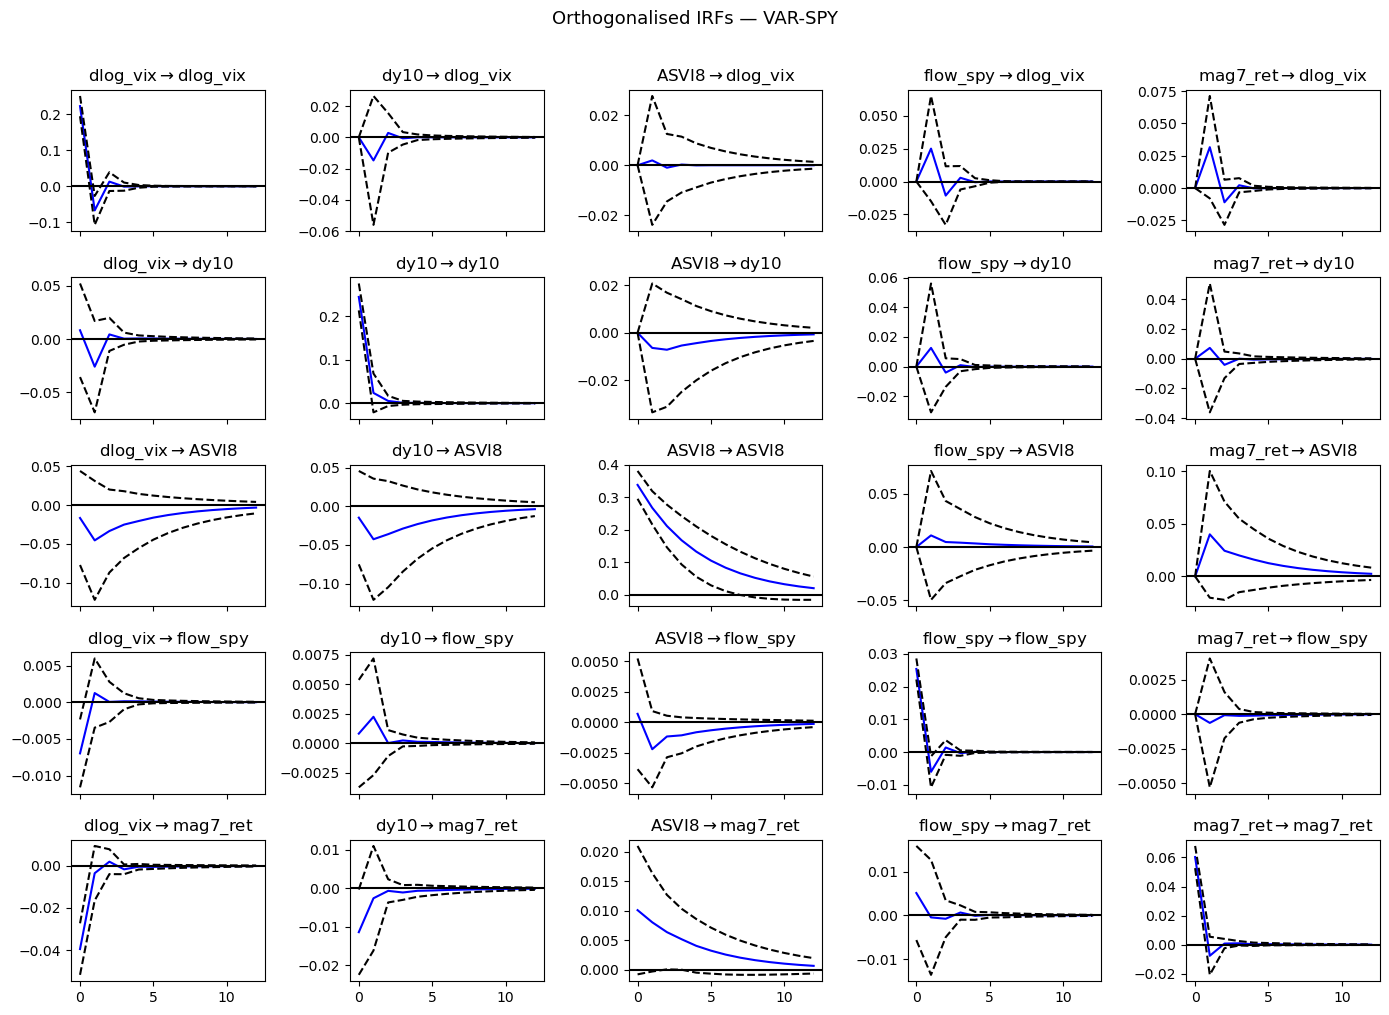

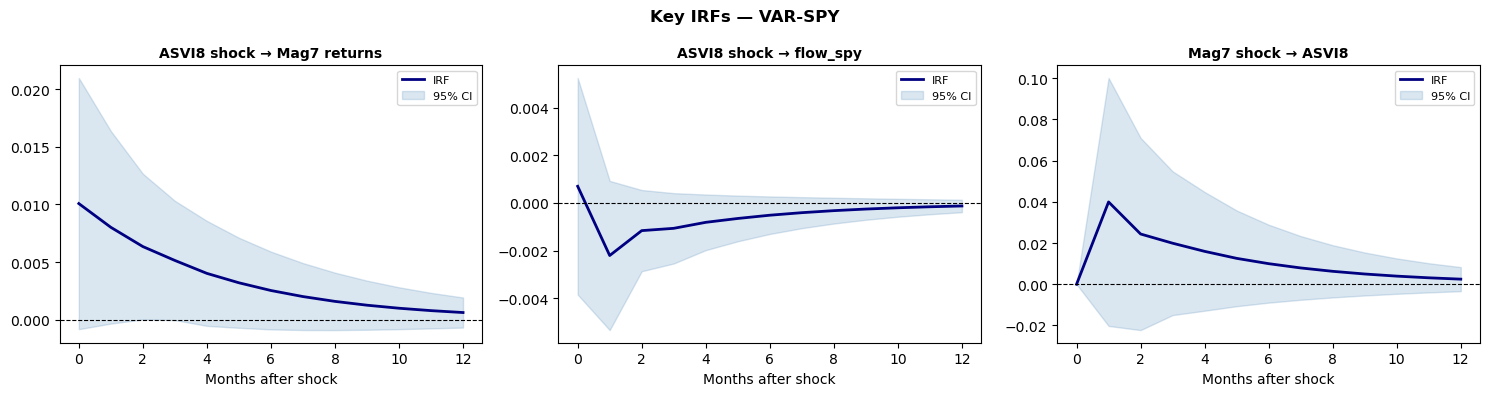

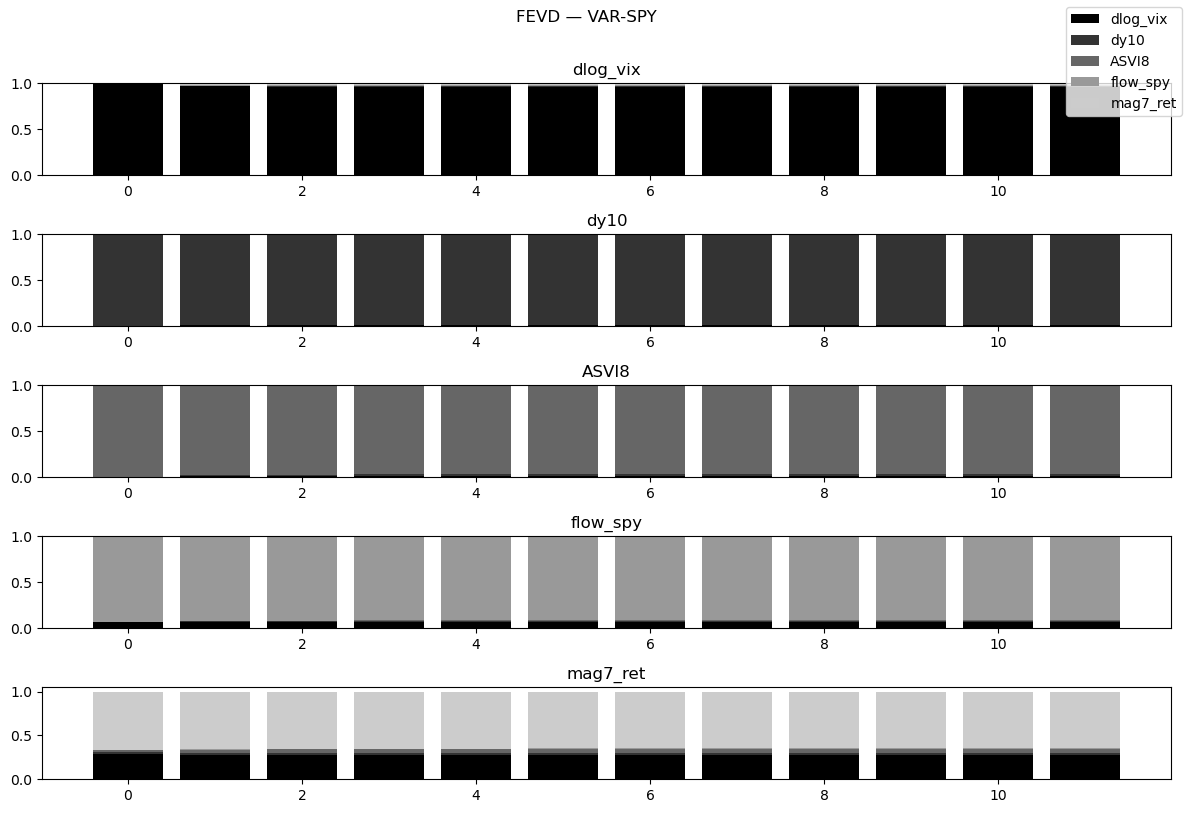


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   28.6% |   27.7% |   27.7%
dy10         |    2.4% |    2.4% |    2.4%
ASVI8        |    1.9% |    4.6% |    4.8%
flow_spy     |    0.5% |    0.5% |    0.5%
mag7_ret     |   66.6% |   64.8% |   64.6%


In [6]:
# ═══════════════════════════════════════════════════════════════════════
# PRIMARY RUNS — ASVI8, FULL SAMPLE (Dec 2015 – Dec 2025)
# ═══════════════════════════════════════════════════════════════════════

results_spy = run_var("VAR-SPY", "flow_spy")


════════════════════════════════════════════════════════════════════
  VAR — VAR-RSP  |  N=121  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.28      -19.17   4.219e-09      -19.24
1     -20.41*     -19.71*  1.362e-09*     -20.13*
2      -20.35      -19.06   1.450e-09      -19.83
3      -20.18      -18.29   1.741e-09      -19.41
4      -20.14      -17.66   1.827e-09      -19.13
-------------------------------------------------
BIC → 1  |  AIC → 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:35:57
--------------------------------------------------------------------
No. of Eq

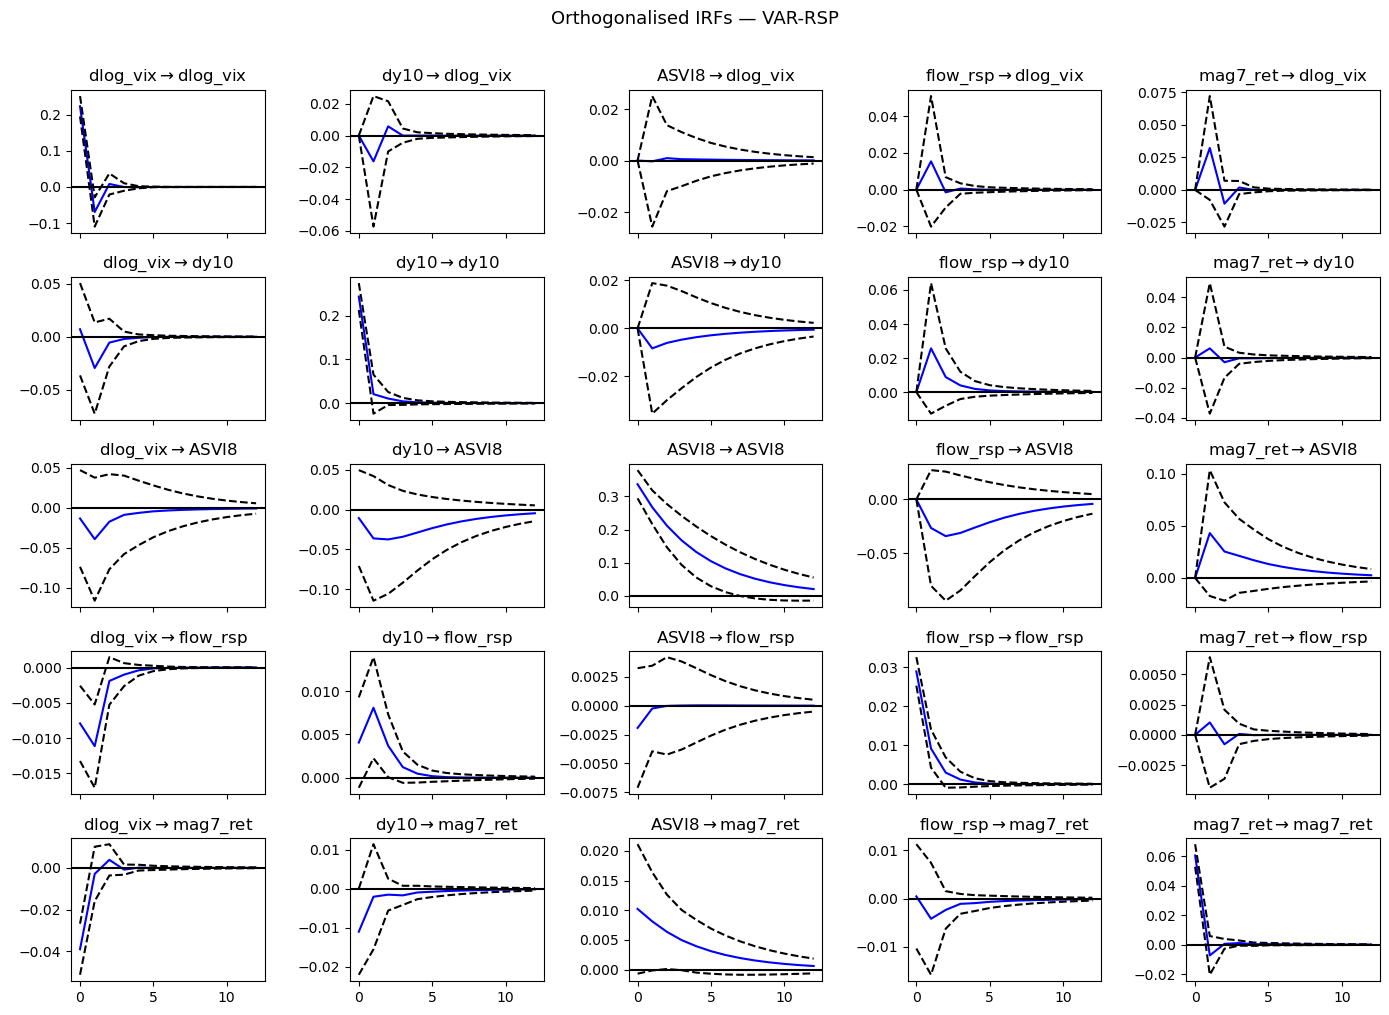

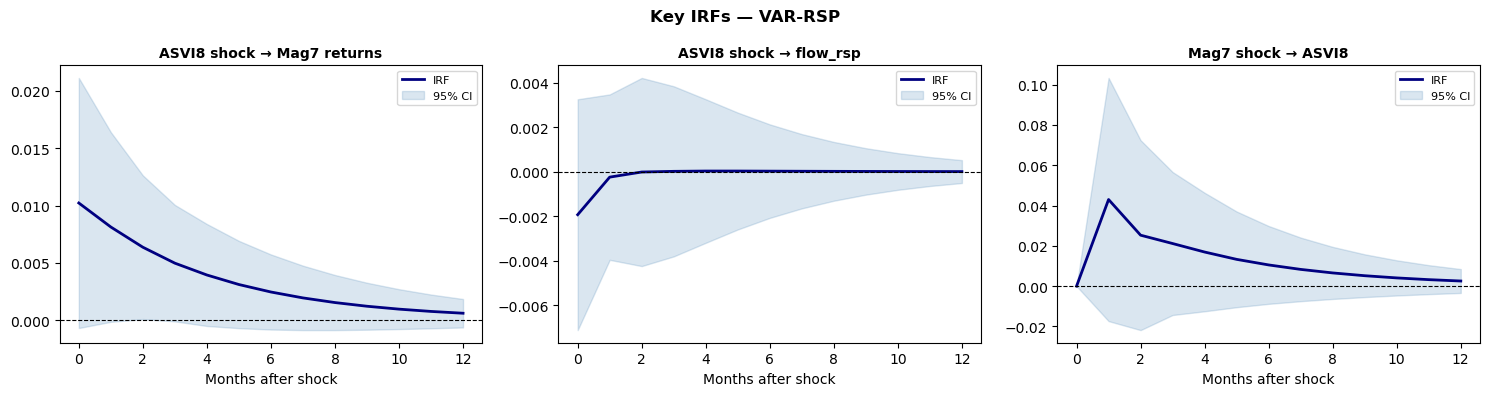

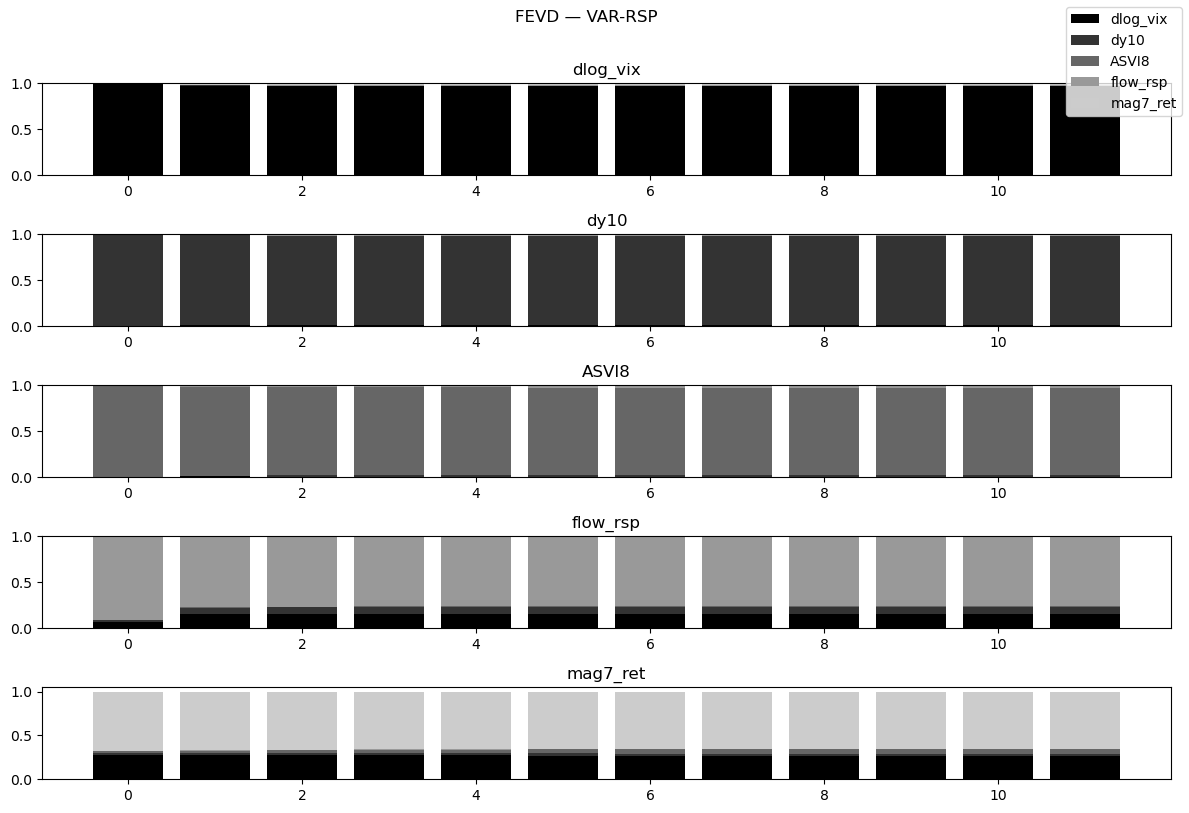


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   28.0% |   27.1% |   27.0%
dy10         |    2.2% |    2.3% |    2.3%
ASVI8        |    1.9% |    4.6% |    4.8%
flow_rsp     |    0.0% |    0.5% |    0.5%
mag7_ret     |   67.8% |   65.5% |   65.3%


In [7]:
results_rsp = run_var("VAR-RSP", "flow_rsp")


════════════════════════════════════════════════════════════════════
  VAR — VAR-VOO  |  N=121  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.72      -20.60   1.008e-09      -20.67
1      -21.69     -20.98*   3.795e-10     -21.41*
2     -21.71*      -20.41  3.741e-10*      -21.18
3      -21.60      -19.71   4.189e-10      -20.84
4      -21.45      -18.97   4.921e-10      -20.45
-------------------------------------------------
BIC → 1  |  AIC → 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:35:58
--------------------------------------------------------------------
No. of Eq

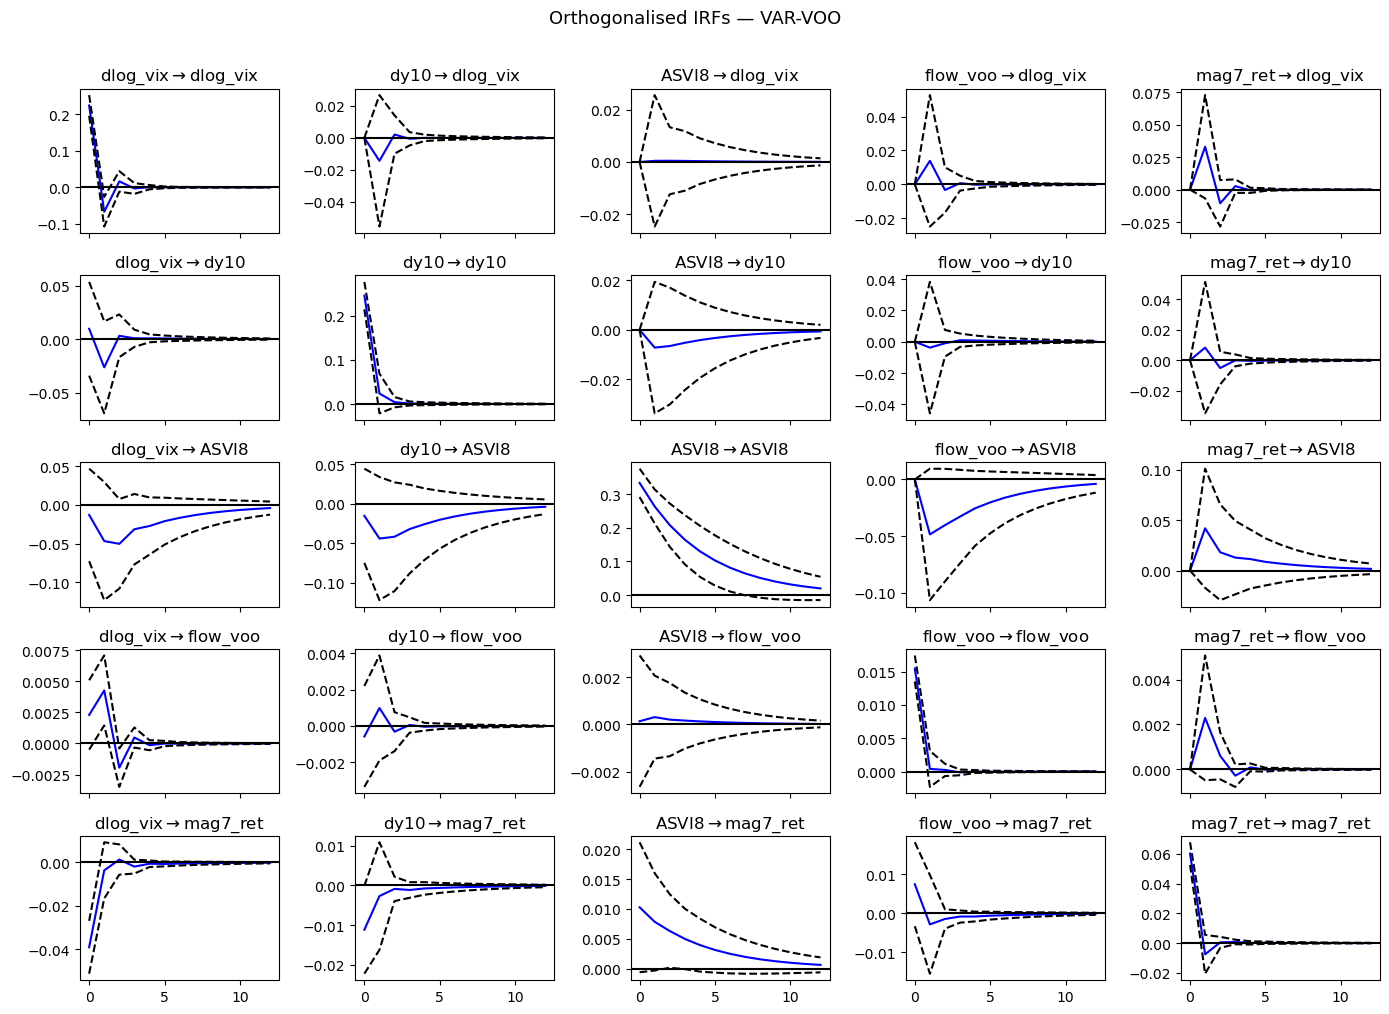

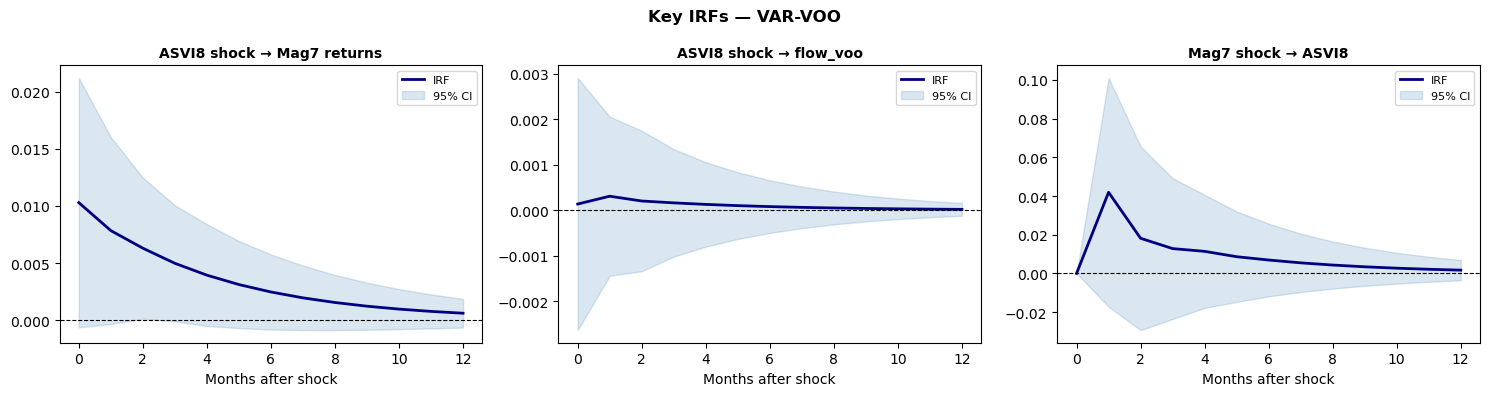

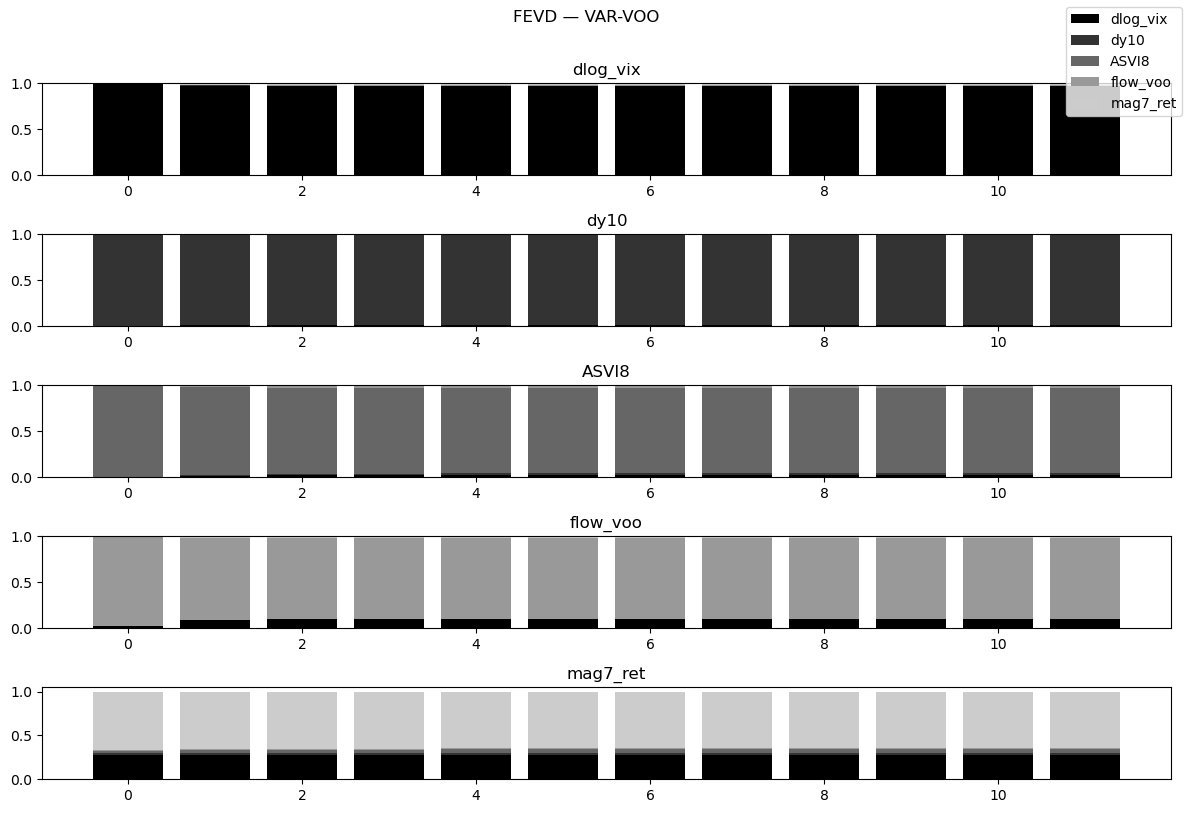


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   28.2% |   27.3% |   27.3%
dy10         |    2.3% |    2.4% |    2.4%
ASVI8        |    1.9% |    4.5% |    4.8%
flow_voo     |    1.0% |    1.2% |    1.2%
mag7_ret     |   66.5% |   64.6% |   64.4%


In [8]:
results_voo = run_var("VAR-VOO", "flow_voo")

2021+ subsample: 61 observations

════════════════════════════════════════════════════════════════════
  VAR — VAR-SPY 2021+  |  N=61  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.55      -19.37   3.229e-09      -19.48
1     -20.61*     -19.54*  1.120e-09*     -20.20*
2      -20.59      -18.62   1.167e-09      -19.83
3      -20.43      -17.56   1.449e-09      -19.32
4      -20.56      -16.80   1.411e-09      -19.10
-------------------------------------------------
BIC → 1  |  AIC → 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:35:59
----------------------------------------

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


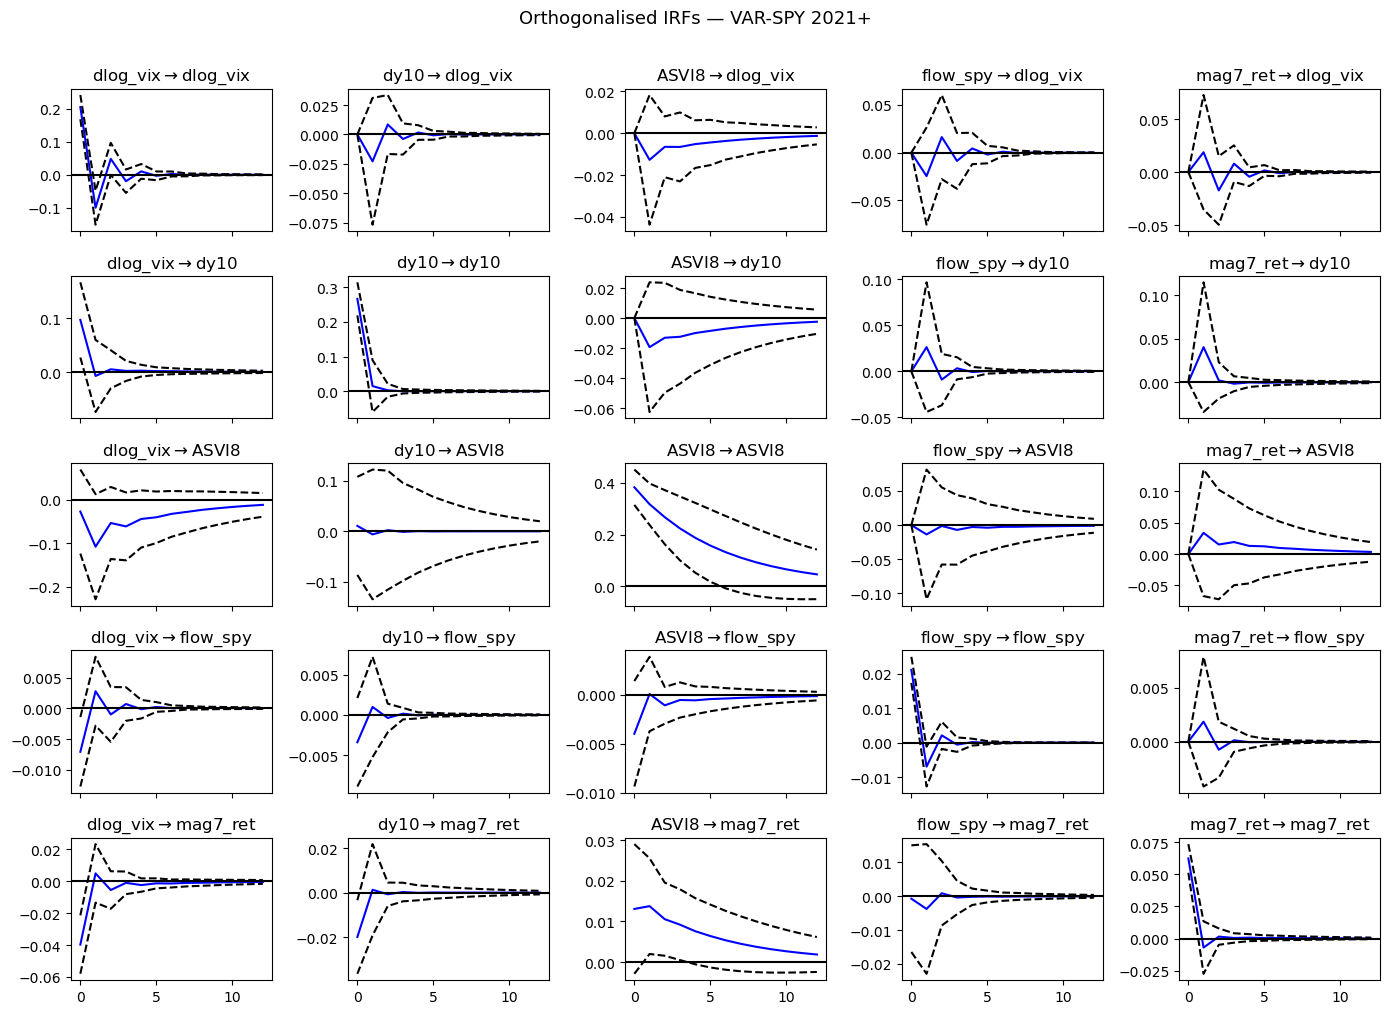

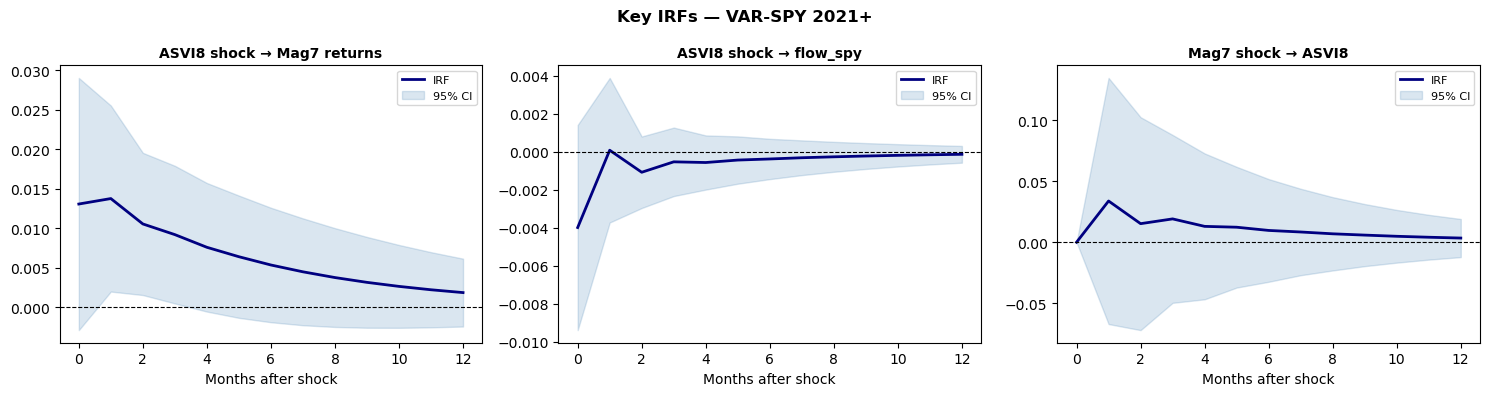

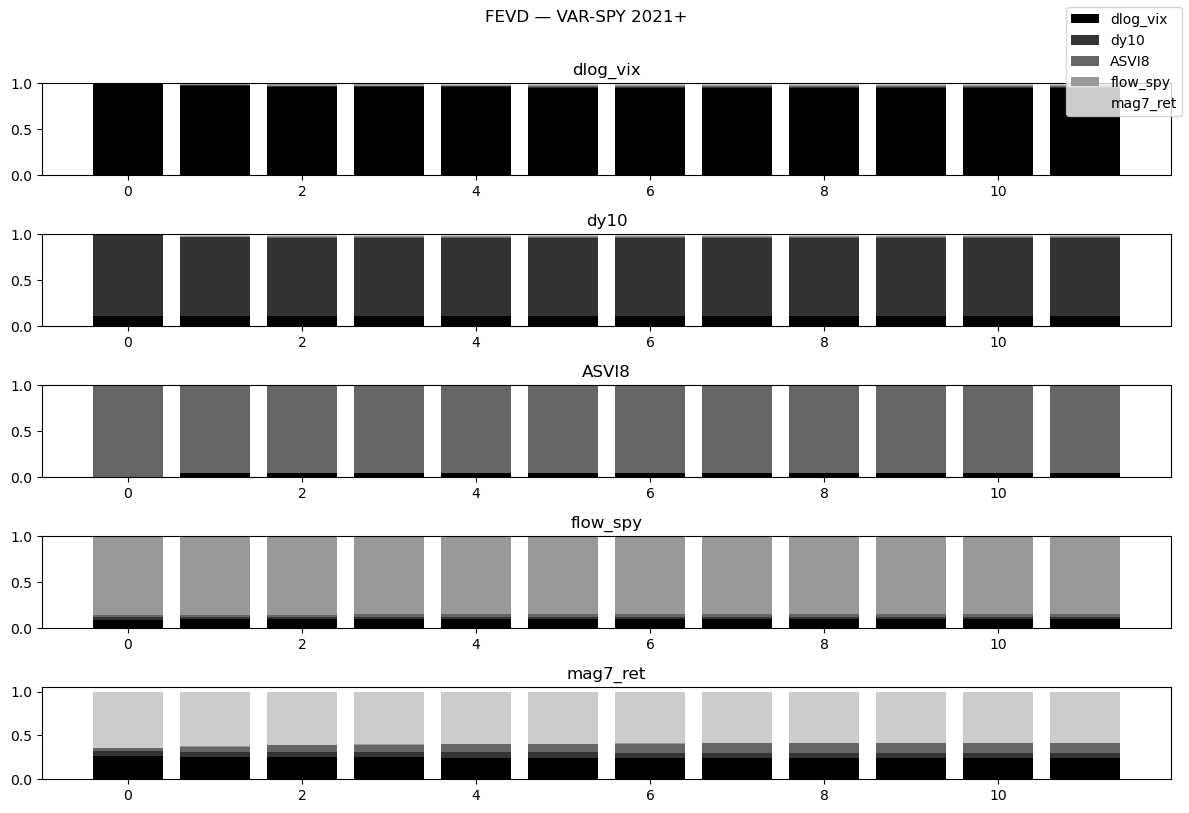


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   26.1% |   24.7% |   24.4%
dy10         |    6.6% |    6.0% |    5.9%
ASVI8        |    2.8% |    9.8% |   10.9%
flow_spy     |    0.0% |    0.2% |    0.2%
mag7_ret     |   64.4% |   59.3% |   58.5%


In [9]:
# ═══════════════════════════════════════════════════════════════════════
# ROBUSTNESS — 2021+ SUBSAMPLE
# ═══════════════════════════════════════════════════════════════════════
# Re-runs all three VARs on the post-COVID subsample (Jan 2021 onwards)
# This tests whether results hold in the period when AI narratives became
# prominent, while avoiding the COVID crash outlier (March 2020) which
# would otherwise dominate VAR dynamics and distort IRFs
# 2021+ (N≈60) provides a clean 5-year window covering the full AI
# narrative buildup period leading into and through the ChatGPT cycle,
# with sufficient observations for reliable 5-variable VAR estimation

var_df_2021 = var_df[var_df["date"] >= "2020-12-31"].copy()
print(f"2021+ subsample: {len(var_df_2021)} observations")  # expect 61, Nobs will be 60 due to lag

results_spy_2021 = run_var("VAR-SPY 2021+", "flow_spy", data=var_df_2021)


════════════════════════════════════════════════════════════════════
  VAR — VAR-RSP 2021+  |  N=61  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -18.78      -18.60   6.993e-09      -18.71
1     -19.89*     -18.82*  2.309e-09*     -19.47*
2      -19.75      -17.78   2.712e-09      -18.98
3      -19.57      -16.70   3.435e-09      -18.45
4      -19.54      -15.77   3.925e-09      -18.07
-------------------------------------------------
BIC → 1  |  AIC → 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:36:00
--------------------------------------------------------------------
No. 

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


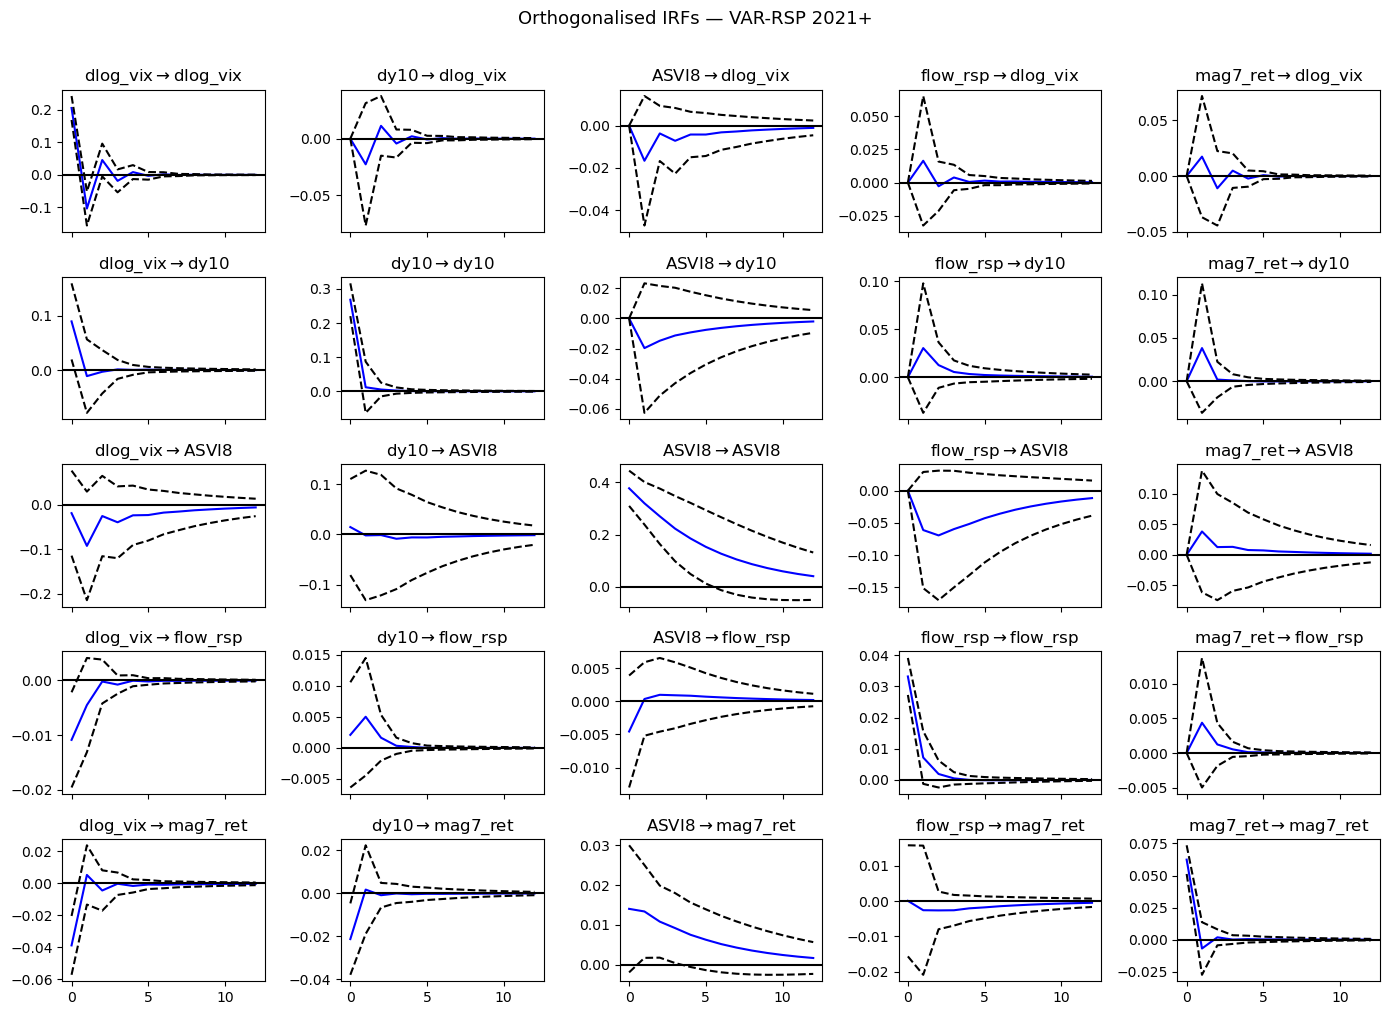

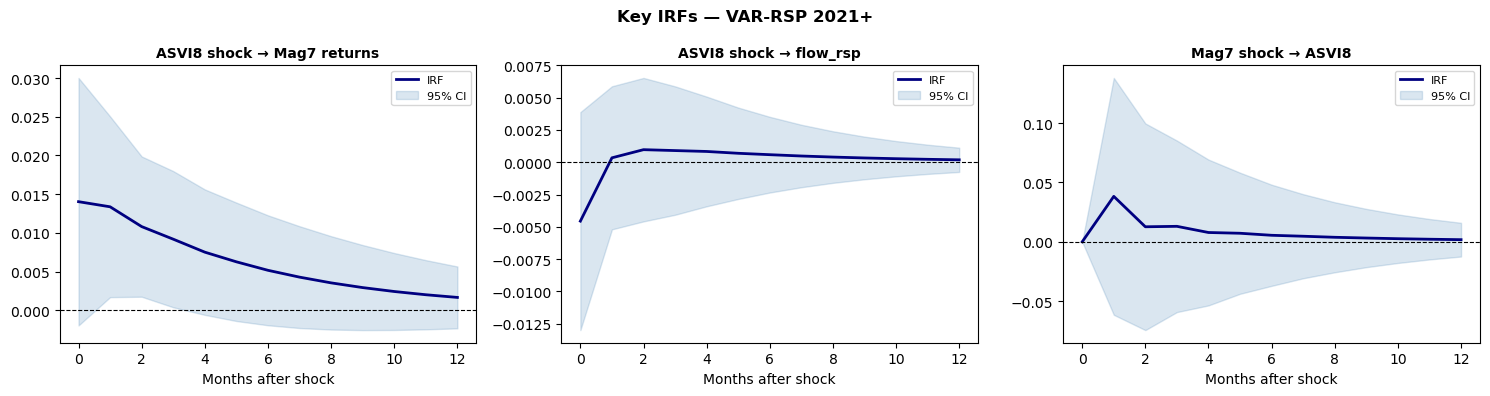

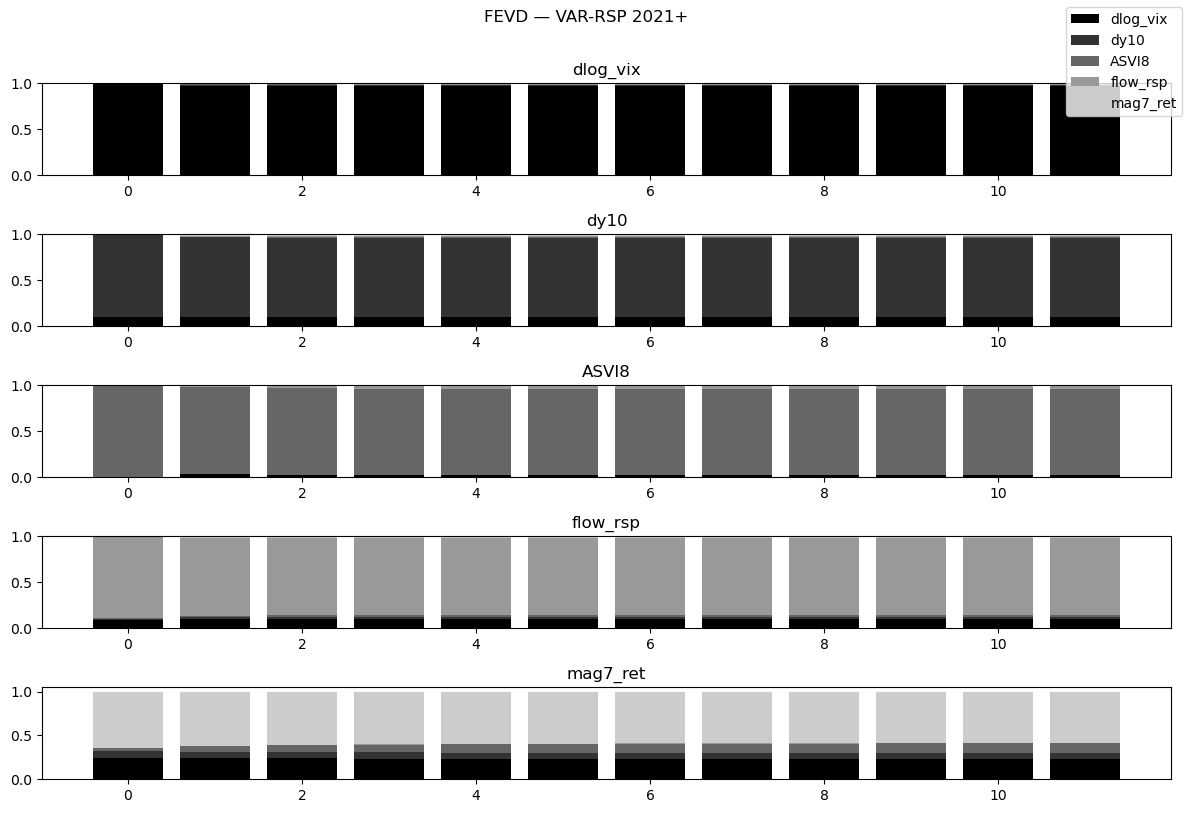


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   24.9% |   23.3% |   23.1%
dy10         |    7.5% |    6.9% |    6.8%
ASVI8        |    3.3% |   10.1% |   11.1%
flow_rsp     |    0.0% |    0.4% |    0.5%
mag7_ret     |   64.4% |   59.3% |   58.5%


In [10]:
results_rsp_2021 = run_var("VAR-RSP 2021+", "flow_rsp", data=var_df_2021)


════════════════════════════════════════════════════════════════════
  VAR — VAR-VOO 2021+  |  N=61  |  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7_ret']
════════════════════════════════════════════════════════════════════

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.57      -20.39   1.165e-09      -20.50
1      -21.96     -20.88*   2.919e-10     -21.54*
2      -21.96      -19.99   2.982e-10      -21.19
3      -22.09      -19.22   2.759e-10      -20.97
4     -22.36*      -18.59  2.344e-10*      -20.89
-------------------------------------------------
BIC → 1  |  AIC → 4  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:36:02
--------------------------------------------------------------------
No. 

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


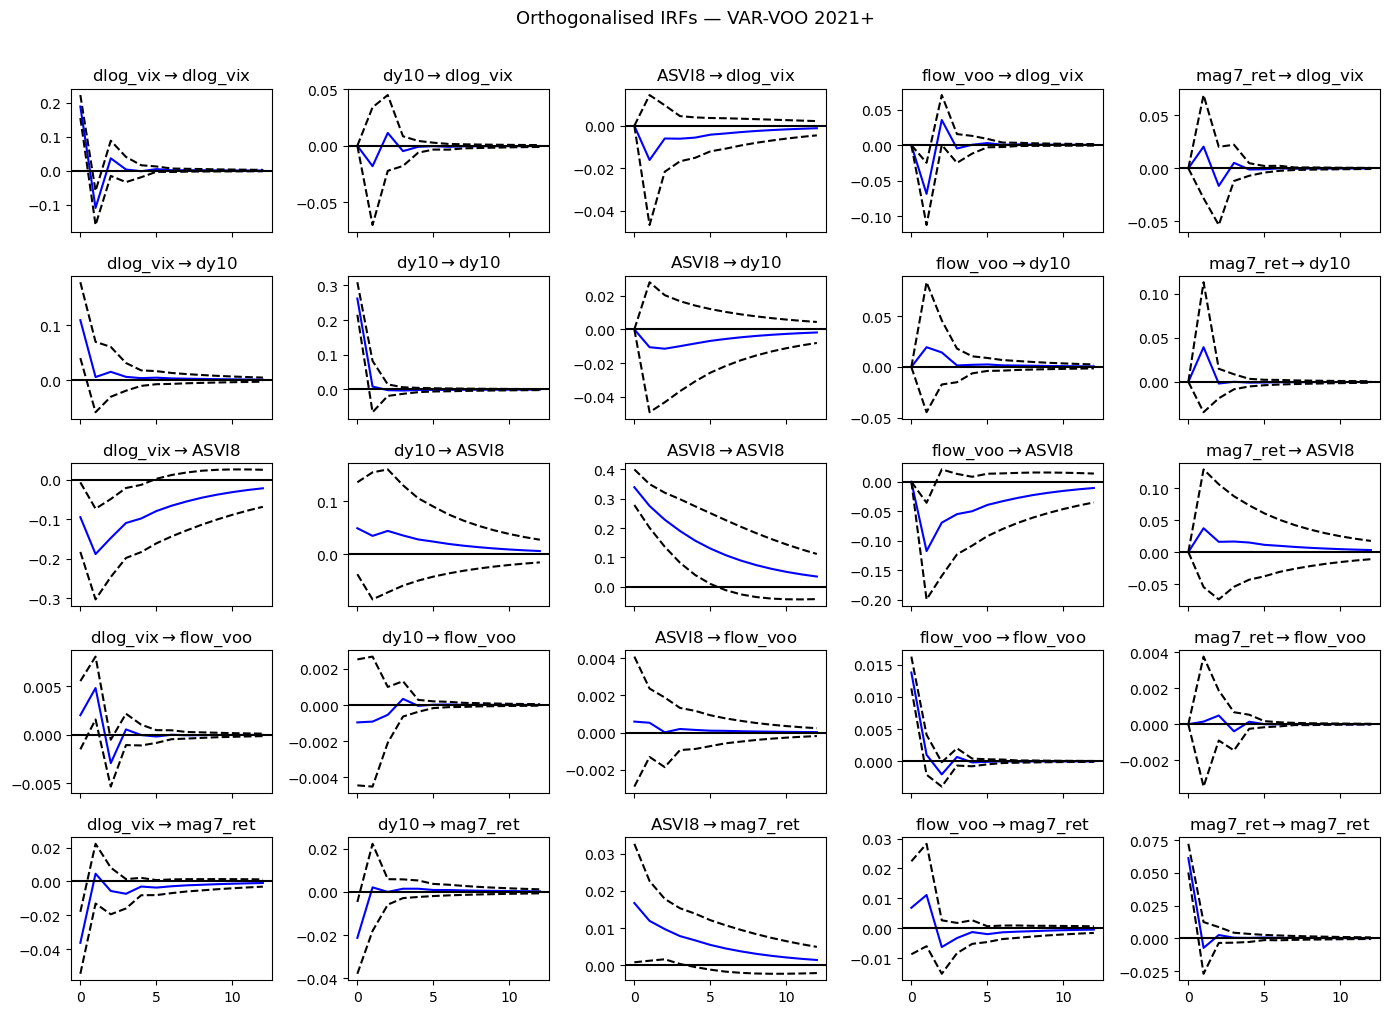

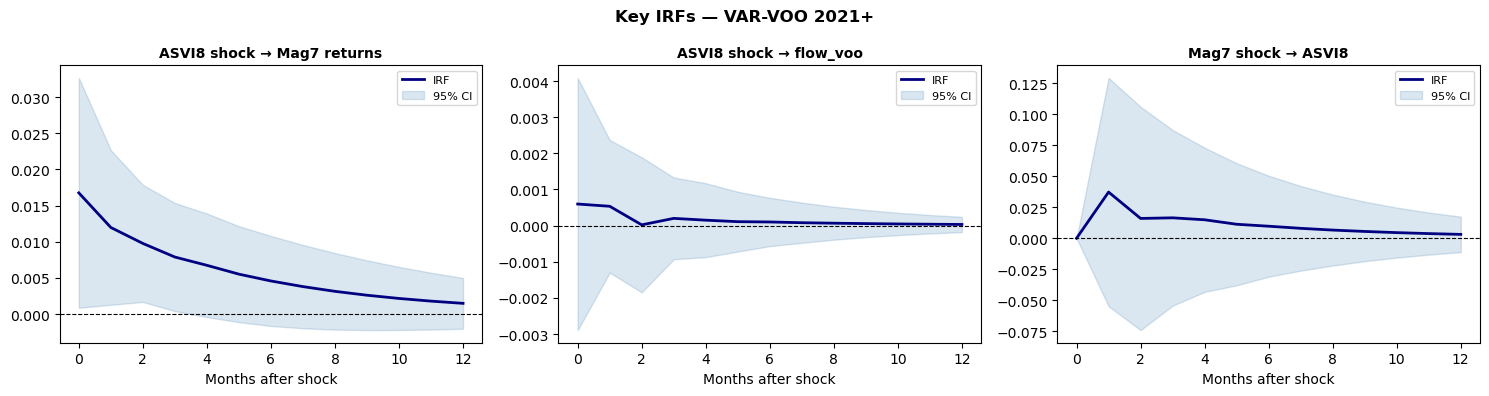

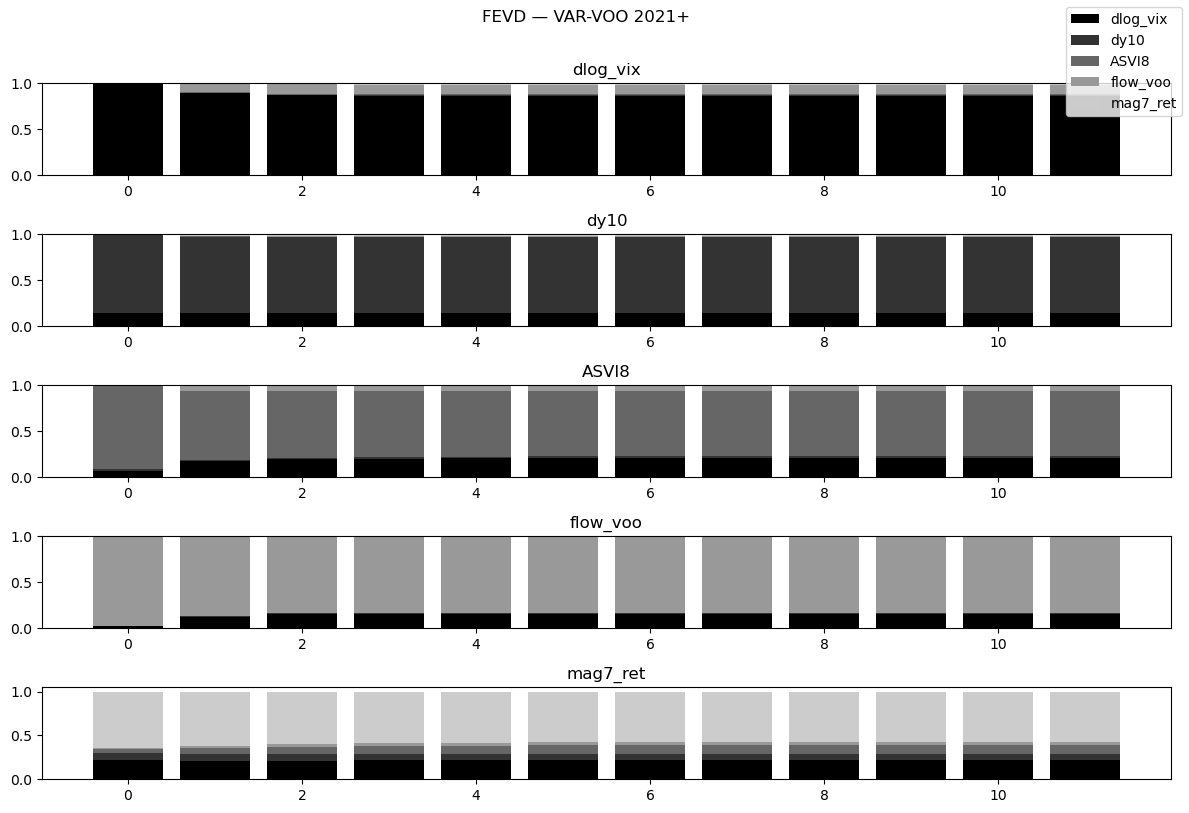


FEVD — share of mag7_ret forecast error variance explained by each variable:
Variable     |      t=1 |      t=6 |     t=12
─────────────────────────────────────────────
dlog_vix     |   22.3% |   21.7% |   21.7%
dy10         |    7.7% |    7.0% |    6.9%
ASVI8        |    4.8% |   10.0% |   10.7%
flow_voo     |    0.8% |    3.4% |    3.5%
mag7_ret     |   64.3% |   57.9% |   57.1%


In [11]:
results_voo_2021 = run_var("VAR-VOO 2021+", "flow_voo", data=var_df_2021)


Full sample, Jan 2016 to Dec 2025: ASVI8 shock -> Mag7 returns (2000 replications)
 h  point  asym_lo  asym_hi  pct_lo  pct_hi  kilian_lo  kilian_hi  asym_excl_0  pct_excl_0  kilian_excl_0
 0 0.0101  -0.0008   0.0210 -0.0023  0.0210    -0.0026     0.0214        False       False          False
 1 0.0080  -0.0003   0.0164 -0.0016  0.0153    -0.0002     0.0165        False       False          False
 2 0.0064   0.0000   0.0127 -0.0010  0.0114     0.0004     0.0130         True       False           True
 3 0.0051  -0.0000   0.0103 -0.0001  0.0093     0.0007     0.0112        False       False           True
 4 0.0040  -0.0005   0.0086 -0.0002  0.0077     0.0004     0.0098        False       False           True
 5 0.0032  -0.0007   0.0071 -0.0002  0.0065     0.0003     0.0087        False       False           True
 6 0.0025  -0.0008   0.0059 -0.0001  0.0056     0.0002     0.0078        False       False           True
 7 0.0020  -0.0009   0.0049 -0.0001  0.0048     0.0002     0.0069   

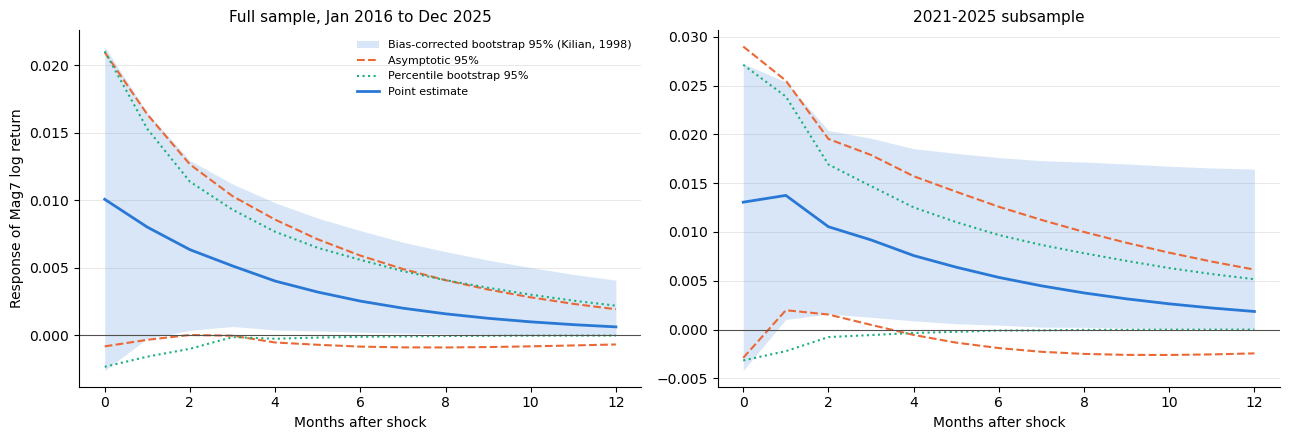

In [12]:
COLS = ["dlog_vix", "dy10", "ASVI8", "flow_spy", "mag7_ret"]   # Cholesky order
REPS = 2000          # bootstrap replications for the bands
BIAS_REPS = 1000     # first-stage replications for Kilian's bias estimate
HORIZON = 12
SEED = 42


# ── VAR helpers (least squares, identical to statsmodels VAR.fit) ──────────
def fit_var(Y, p):
    """Return intercept c, list of lag matrices [A1..Ap], residuals U, Sigma_u."""
    T, K = Y.shape
    X = np.column_stack([np.ones(T - p)] + [Y[p - j - 1:T - j - 1] for j in range(p)])
    B = np.linalg.lstsq(X, Y[p:], rcond=None)[0]
    U = Y[p:] - X @ B
    sigma = U.T @ U / (T - p - X.shape[1])       # degrees-of-freedom adjusted
    A = [B[1 + j * K:1 + (j + 1) * K].T for j in range(p)]
    return B[0], A, U, sigma


def orth_irf(A, sigma, horizon):
    """Orthogonalized (Cholesky) impulse responses, shape (horizon+1, K, K)."""
    K = sigma.shape[0]
    p = len(A)
    P = np.linalg.cholesky(sigma)
    Phi = [np.eye(K)]
    for h in range(1, horizon + 1):
        Phi.append(sum(A[j] @ Phi[h - 1 - j] for j in range(min(p, h))))
    return np.array([Ph @ P for Ph in Phi])


def simulate(c, A, U, Y_init, T, rng):
    """Recursive bootstrap sample of length T started at the actual first p rows."""
    p, K = len(A), len(c)
    Y = np.empty((T, K))
    Y[:p] = Y_init
    u_star = U[rng.integers(0, len(U), size=T - p)]
    for t in range(p, T):
        Y[t] = c + sum(A[j] @ Y[t - 1 - j] for j in range(p)) + u_star[t - p]
    return Y


def max_modulus(A):
    """Largest eigenvalue modulus of the companion matrix (stable if < 1)."""
    K, p = A[0].shape[0], len(A)
    C = np.zeros((K * p, K * p))
    C[:K] = np.hstack(A)
    if p > 1:
        C[K:, :-K] = np.eye(K * (p - 1))
    return np.abs(np.linalg.eigvals(C)).max()


def bias_correct(A, bias):
    """Kilian (1998) correction, shrunk if it would make the VAR non-stationary."""
    delta = 1.0
    A_bc = [a - b for a, b in zip(A, bias)]
    while max_modulus(A_bc) >= 1 and delta > 0:
        delta -= 0.01
        A_bc = [a - delta * b for a, b in zip(A, bias)]
    return A_bc


# ── Main routine ────────────────────────────────────────────────────────────
def bootstrap_irf_bands(data, cols, impulse, response, p=1, horizon=HORIZON,
                        reps=REPS, bias_reps=BIAS_REPS, seed=SEED):
    Y = data[cols].to_numpy(dtype=float)
    T = len(Y)
    i_imp, i_resp = cols.index(impulse), cols.index(response)
    rng = np.random.default_rng(seed)

    c, A, U, sigma = fit_var(Y, p)
    U = U - U.mean(axis=0)
    point = orth_irf(A, sigma, horizon)[:, i_resp, i_imp]

    # Asymptotic (delta-method) bands from statsmodels, as in the main text
    irf_sm = VAR(Y).fit(p).irf(horizon)
    assert np.allclose(irf_sm.orth_irfs[:, i_resp, i_imp], point)
    se = irf_sm.stderr(orth=True)[:, i_resp, i_imp]

    # (a) Plain percentile bootstrap
    draws_pct, A_draws = [], []
    for _ in range(reps):
        _, A_b, _, s_b = fit_var(simulate(c, A, U, Y[:p], T, rng), p)
        A_draws.append(A_b)
        draws_pct.append(orth_irf(A_b, s_b, horizon)[:, i_resp, i_imp])
    draws_pct = np.array(draws_pct)

    # (b) Kilian (1998) bias-corrected bootstrap-after-bootstrap
    bias = [np.mean([Ad[j] for Ad in A_draws[:bias_reps]], axis=0) - A[j] for j in range(p)]
    A_bc = bias_correct(A, bias)
    c_bc = (np.eye(len(cols)) - sum(A_bc)) @ Y.mean(axis=0)   # keeps the sample mean
    draws_kil = []
    for _ in range(reps):
        _, A_b, _, s_b = fit_var(simulate(c_bc, A_bc, U, Y[:p], T, rng), p)
        draws_kil.append(orth_irf(bias_correct(A_b, bias), s_b, horizon)[:, i_resp, i_imp])
    draws_kil = np.array(draws_kil)

    z = 1.959964
    out = pd.DataFrame({"h": np.arange(horizon + 1), "point": point,
                        "asym_lo": point - z * se, "asym_hi": point + z * se})
    out["pct_lo"], out["pct_hi"] = np.percentile(draws_pct, [2.5, 97.5], axis=0)
    out["kilian_lo"], out["kilian_hi"] = np.percentile(draws_kil, [2.5, 97.5], axis=0)
    for m in ["asym", "pct", "kilian"]:
        out[f"{m}_excl_0"] = (out[f"{m}_lo"] > 0) | (out[f"{m}_hi"] < 0)
    return out


if __name__ == "__main__":
    df = None
    for f in ["spy_clean.csv", "vix_clean.csv", "dgs10_clean.csv",
              "AIStocks_ASVI8_Monthly.csv", "mag7_clean.csv"]:
        part = pd.read_csv(f, parse_dates=["date"])
        df = part if df is None else df.merge(part, on="date", how="inner")
    df = df.sort_values("date").reset_index(drop=True)

    samples = {
        "full": ("Full sample, Jan 2016 to Dec 2025", df),
        # Dec 2020 is kept as the initial lag: estimation runs Jan 2021 to Dec 2025 (60 obs)
        "2021": ("2021-2025 subsample", df[df["date"] >= "2020-12-31"]),
    }
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, (key, (title, d)) in zip(axes, samples.items()):
        tab = bootstrap_irf_bands(d, COLS, impulse="ASVI8", response="mag7_ret")
        tab.to_csv(f"bootstrap_irf_{key}.csv", index=False)
        print(f"\n{title}: ASVI8 shock -> Mag7 returns ({REPS} replications)")
        print(tab.round(4).to_string(index=False))

        h = tab["h"]
        ax.fill_between(h, tab["kilian_lo"], tab["kilian_hi"], color="#2a78d6", alpha=0.18,
                        linewidth=0, label="Bias-corrected bootstrap 95% (Kilian, 1998)")
        ax.plot(h, tab["asym_lo"], color="#eb6834", lw=1.5, ls="--", label="Asymptotic 95%")
        ax.plot(h, tab["asym_hi"], color="#eb6834", lw=1.5, ls="--")
        ax.plot(h, tab["pct_lo"], color="#1baf7a", lw=1.5, ls=":", label="Percentile bootstrap 95%")
        ax.plot(h, tab["pct_hi"], color="#1baf7a", lw=1.5, ls=":")
        ax.plot(h, tab["point"], color="#2a78d6", lw=2, label="Point estimate")
        ax.axhline(0, color="#52514e", lw=0.8)
        ax.grid(axis="y", color="#e6e5e0", lw=0.6)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Months after shock")
        ax.set_xticks(range(0, 13, 2))
    axes[0].set_ylabel("Response of Mag7 log return")
    axes[0].legend(fontsize=8, loc="upper right", frameon=False)
    plt.tight_layout()
    plt.savefig("bootstrap_irf_comparison.png", dpi=300)
    plt.show()
